# FRED-MD real-data exploration: WERM with CV-selected change-point count

This notebook is deliberately separate from `FRED-MD Real Data Experiment.ipynb`.
It audits the bundled McScan and DPDU reference protocols, diagnoses why the
previous unpenalized WERM CV curves prefer zero change points, and runs a
controlled WERM sensitivity study without changing the estimator's semantics.

The primary target is not merely a nonzero answer. It is a reproducible,
reasonably reference-aligned least-squares or Huber configuration for which
honest cross-validation jointly selects the number of segments and the
coefficient regularization strength, with a clear score margin and a change
date reasonably close to a published FRED-MD change.

**Index convention.** Python indices below are zero-based and identify the first
observation in the new segment. The bundled McScan paper reports 1974-02,
2010-05, and 2019-05, corresponding to Python indices 169, 604, and 712 in the
stored data. DPDU uses a different 2000--2022 experiment and reports 2008-06
and 2020-01, indices 581 and 720 in this longer panel.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import pickle
import platform
import sys
import time
import warnings

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import scipy.optimize
from joblib import Parallel, delayed

import WERM.estimators

ROOT = Path.cwd()
DATA_PATH = ROOT / "FRED-MD data" / "fredmd_data.pkl"
RESULT_DIR = ROOT / "results" / "FRED-MD_real-data-exploration"
FIGURE_DIR = ROOT / "figures" / "FRED-MD_real-data-exploration"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

N_JOBS = min(20, os.cpu_count() or 1)
print({
    "python": sys.version.split()[0], "platform": platform.platform(),
    "numpy": np.__version__, "scipy": scipy.__version__,
    "jax": jax.__version__, "n_jobs": N_JOBS,
})

{'python': '3.10.18', 'platform': 'Linux-6.11.0-29-generic-x86_64-with-glibc2.39', 'numpy': '2.2.5', 'scipy': '1.15.3', 'jax': '0.4.35', 'n_jobs': 20}


In [2]:
with DATA_PATH.open("rb") as handle:
    fred = pickle.load(handle)

X = np.asarray(fred["X"], dtype=float)
y = np.asarray(fred["y"], dtype=float).reshape(-1)
dates = np.asarray(fred["date"]).astype(str).reshape(-1)
n, p = X.shape
assert y.shape == (n,) and dates.shape == (n,)
assert np.isfinite(X).all() and np.isfinite(y).all()

data_hash = hashlib.blake2b(
    np.ascontiguousarray(X).tobytes() + np.ascontiguousarray(y).tobytes(),
    digest_size=16,
).hexdigest()
reference_dates = {
    "McScan": ["1974-02", "2010-05", "2019-05"],
    "DPDU_different_window": ["2008-06", "2020-01"],
}
reference_indices = {
    name: [int(np.flatnonzero(dates == value)[0]) for value in values]
    for name, values in reference_dates.items()
}

data_audit = {
    "shape_X": list(X.shape), "shape_y": list(y.shape),
    "date_start": dates[0], "date_end": dates[-1], "data_hash": data_hash,
    "X_mean_range": [float(X.mean(0).min()), float(X.mean(0).max())],
    "X_sd_range": [float(X.std(0).min()), float(X.std(0).max())],
    "y_mean": float(y.mean()), "y_sd": float(y.std()),
    "y_min": float(y.min()), "y_max": float(y.max()),
    "reference_indices": reference_indices,
}
pd.Series(data_audit, name="value")

shape_X                                                     [773, 114]
shape_y                                                          [773]
date_start                                                     1960-01
date_end                                                       2024-05
data_hash                             0ea49ecc65b741d7217c33fce81b65f6
X_mean_range               [-0.015170381327519805, 0.0182312819330829]
X_sd_range                   [0.14476043306001327, 0.9978302666767077]
y_mean                                                        0.006443
y_sd                                                          0.880242
y_min                                                        -7.487977
y_max                                                         6.428431
reference_indices    {'McScan': [169, 604, 712], 'DPDU_different_wi...
Name: value, dtype: object

## Reference-protocol audit

| Component | Bundled McScan FRED-MD | Bundled DPDU FRED application | This notebook's primary WERM run |
|---|---|---|---|
| Window | 1960-01--2024-05, n=773 | 2000-01--2022-12, n=275 | McScan's stored n=773 panel |
| Response | transformed, standardized, 99.9%-winsorized INDPRO at t+1 | monthly log growth of IP at t | same stored McScan response |
| Predictors | six PCA factors + 108 idiosyncratic components at t, p=114 | 116 lagged macro variables after dropping missing columns | same stored McScan design, no extra transformation initially |
| Heavy tails | global 99.9% winsorization after per-series FRED transformations and standardization | outlier removal through `fbi` | retain McScan winsorization initially |
| Count selection | automatic threshold + solution-path elbow; not predictive CV | DPDU partition penalty and Lasso parameter chosen jointly | segment count and coefficient penalty chosen jointly |
| Validation | none for threshold in the real-data call | odd/even split, least-squares prediction error | odd/even interlaced CV first |
| Published estimates | 1974-02, 2010-05, 2019-05 | refined 2008-06, 2020-01 | estimated below |

The experiments are similar in scientific question but not identical estimators.
McScan detects covariance changes and does not estimate segment regressions for
its threshold. DPDU and WERM use predictive regression losses. Therefore exact
equality of change dates is not expected, but proximity to the financial-crisis
or COVID regimes is a meaningful validation target.

A crucial audit finding is that `weighted_erm_joint_cv` currently refits each
validation segment with `M_scorer`, not with the fitting loss `M`. Existing
notebook calls used absolute error as `M_scorer`, so least-squares/Huber
detection was followed by nonsmooth absolute-loss coefficient refits. The local
routine below keeps the estimator unchanged but makes the validation refit loss
explicit. The primary run uses `refit_loss == fit_loss`; `score_loss` is absolute loss only on held-out predictions.

In [3]:
def squared_loss(prediction, target):
    return jnp.square(prediction - target)


def absolute_loss(prediction, target):
    return jnp.abs(prediction - target)


def make_huber(epsilon):
    epsilon = float(epsilon)
    def huber(prediction, target):
        residual = prediction - target
        absolute = jnp.abs(residual)
        return jnp.where(
            absolute <= epsilon,
            0.5 * jnp.square(residual),
            epsilon * (absolute - 0.5 * epsilon),
        )
    return huber


def safe_scale(values):
    value = float(np.std(values))
    return value if np.isfinite(value) and value > 1e-12 else 1.0


def transform_design(X_train, X_test=None, mode="reference"):
    '''Use the stored factor/idiosyncratic design, or a fold-local z-score sensitivity.'''
    X_train = np.asarray(X_train, dtype=float)
    if mode == "reference":
        return X_train, None if X_test is None else np.asarray(X_test, dtype=float)
    if mode != "fold-zscore":
        raise ValueError("design mode must be 'reference' or 'fold-zscore'")
    mean = X_train.mean(axis=0)
    scale = X_train.std(axis=0)
    scale[~np.isfinite(scale) | (scale < 1e-12)] = 1.0
    transformed_train = (X_train - mean) / scale
    transformed_test = None if X_test is None else (np.asarray(X_test) - mean) / scale
    return transformed_train, transformed_test

In [4]:
def werm_cv_surface(
    X, y, *, fit_loss, refit_loss, score_loss, loss_name,
    segment_counts=(1, 2, 3, 4, 5), constants=(0.0,),
    penalty_norm="none", delta_fraction=1/40, num_folds=2,
    design_mode="reference", standardize_y=False, n_jobs=N_JOBS,
):
    '''Exact WERM fits with interlaced CV and explicit refit/scoring losses.'''
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    n_samples, p_features = X.shape
    segment_counts = tuple(int(value) for value in segment_counts)
    constants = (0.0,) if penalty_norm == "none" else tuple(float(v) for v in constants)
    candidates = [(segments, constant) for segments in segment_counts for constant in constants]
    folds = [np.arange(v, n_samples, int(num_folds), dtype=int) for v in range(int(num_folds))]

    def coefficient_lambda(constant, training_size):
        if penalty_norm == "none":
            return 0.0
        return float(constant) * np.sqrt(2.0 * np.log(p_features) / training_size)

    def penalty(beta, value):
        if penalty_norm == "none":
            return jnp.array(0.0)
        if penalty_norm == "l1":
            return value * jnp.sum(jnp.abs(beta))
        if penalty_norm == "l2":
            return value * jnp.sum(jnp.square(beta))
        raise ValueError("penalty_norm must be none, l1, or l2")

    def fit_detector(X_fit, y_fit, candidate):
        segments, constant = candidate
        lam = coefficient_lambda(constant, len(y_fit))
        P_func = lambda beta: penalty(beta, lam)
        minimum = max(
            int(np.ceil(len(y_fit) / 50.0)),
            int(float(delta_fraction) * len(y_fit)),
            1,
        )
        return np.asarray(WERM.estimators.weighted_erm(
            X_fit, y_fit, fit_loss, L=segments, Delta_n=minimum,
            gamma=0.0, L_is_upper_bound=False, brute_force=False,
            P_func=P_func,
        ), dtype=int).reshape(-1)

    def fit_segment_beta(X_segment, y_segment, lam):
        def objective(beta):
            prediction = X_segment @ beta
            return jnp.mean(refit_loss(prediction, y_segment)) + penalty(beta, lam)
        result = scipy.optimize.minimize(
            objective, 0.1 * np.ones(X_segment.shape[1]),
            jac=jax.grad(objective), method="L-BFGS-B",
            options={"maxiter": 1000, "ftol": 1e-10},
        )
        if not np.isfinite(result.fun):
            raise RuntimeError("nonfinite segment refit")
        return np.asarray(result.x)

    def evaluate_fold(candidate, fold_number):
        test_indices = folds[fold_number]
        train_indices = np.sort(np.concatenate([
            fold for index, fold in enumerate(folds) if index != fold_number
        ]))
        X_train, X_test = transform_design(
            X[train_indices], X[test_indices], mode=design_mode
        )
        response_scale = safe_scale(y[train_indices]) if standardize_y else 1.0
        y_train = y[train_indices] / response_scale
        y_test = y[test_indices] / response_scale
        detected = fit_detector(X_train, y_train, candidate)
        mapped = np.asarray([
            train_indices[value] for value in detected
            if 0 < value < len(train_indices)
        ], dtype=int)
        boundaries = np.concatenate(([0], mapped, [n_samples]))
        lam = coefficient_lambda(candidate[1], len(train_indices))
        betas = []
        for start, end in zip(boundaries[:-1], boundaries[1:]):
            mask = (train_indices >= start) & (train_indices < end)
            if not np.any(mask):
                raise RuntimeError("empty validation refit segment")
            betas.append(fit_segment_beta(X_train[mask], y_train[mask], lam))
        score = 0.0
        for position, original_index in enumerate(test_indices):
            segment = min(
                np.searchsorted(boundaries[1:], original_index, side="right"),
                len(betas) - 1,
            )
            prediction = X_test[position:position + 1] @ betas[segment]
            score += float(np.asarray(score_loss(prediction, y_test[position:position + 1]))[0])
        return score, mapped.tolist()

    started = time.perf_counter()
    def evaluate_candidate(candidate):
        try:
            values = [evaluate_fold(candidate, fold_number) for fold_number in range(num_folds)]
            return sum(item[0] for item in values), [item[1] for item in values], None
        except Exception as exc:
            return float("inf"), [], repr(exc)

    evaluated = Parallel(n_jobs=int(n_jobs), verbose=0)(
        delayed(evaluate_candidate)(candidate) for candidate in candidates
    )
    scores = np.asarray([item[0] for item in evaluated], dtype=float)
    if not np.isfinite(scores).any():
        raise RuntimeError("all CV candidates failed")
    best_index = int(np.nanargmin(scores))
    best = candidates[best_index]

    X_full, _ = transform_design(X, mode=design_mode)
    full_response_scale = safe_scale(y) if standardize_y else 1.0
    full_cp = fit_detector(X_full, y / full_response_scale, best)
    baseline = min(
        scores[index] for index, candidate in enumerate(candidates)
        if candidate[0] == 1 and np.isfinite(scores[index])
    )
    rows = []
    for candidate, score, details in zip(candidates, scores, evaluated):
        rows.append({
            "segments": candidate[0], "change_points": candidate[0] - 1,
            "constant": candidate[1], "cv_total": float(score),
            "cv_mean": float(score / n_samples),
            "difference_from_best_1_segment": float((score - baseline) / n_samples),
            "fold_change_points": details[1], "error": details[2],
        })
    return {
        "loss": loss_name, "refit_loss": getattr(refit_loss, "__name__", "callable"),
        "score_loss": getattr(score_loss, "__name__", "callable"),
        "penalty_norm": penalty_norm, "constants": list(constants),
        "delta_fraction": float(delta_fraction), "num_folds": int(num_folds),
        "design_mode": design_mode, "standardize_y": bool(standardize_y),
        "selected_segments": int(best[0]), "selected_change_points": int(best[0] - 1),
        "selected_constant": float(best[1]), "estimated_change_points": full_cp.tolist(),
        "estimated_dates": dates[full_cp].tolist(), "score_curve": rows,
        "elapsed_seconds": time.perf_counter() - started,
    }

## Stage 1: protocol-faithful odd/even CV

The stored McScan preprocessing is held fixed. We add an L1 coefficient
penalty because p=114 and an odd/even training segment can contain fewer
observations than predictors; unpenalized segment refits are therefore a
high-variance baseline, not the most comparable high-dimensional regression
fit. Candidate segment counts are 1--5 and C multiplies
`sqrt(2 log(p) / n_train)` in the coefficient penalty.

Least squares uses squared loss for segmentation and hard segment refits. Huber uses
epsilon 1.35 for both fitting stages. In both cases, held-out predictions are
scored only by absolute loss, exactly as required by the WERM-CV interface.

In [5]:
primary_specs = [
    {
        "fit_loss": squared_loss, "refit_loss": squared_loss,
        "score_loss": absolute_loss, "loss_name": "least-squares",
    },
    {
        "fit_loss": make_huber(1.35), "refit_loss": make_huber(1.35),
        "score_loss": absolute_loss, "loss_name": "Huber-eps1.35",
    },
]
primary_results = []
for specification in primary_specs:
    print("Running", specification["loss_name"], flush=True)
    result = werm_cv_surface(
        X, y, **specification,
        segment_counts=(1, 2, 3, 4, 5),
        constants=(0.15, 0.3, 0.5, 0.75, 1.0, 2.0),
        penalty_norm="l1", delta_fraction=1/40,
        num_folds=2, design_mode="reference", standardize_y=False,
    )
    primary_results.append(result)
    print({key: result[key] for key in (
        "loss", "selected_change_points", "selected_constant",
        "estimated_change_points", "estimated_dates", "elapsed_seconds"
    )})

primary_table = pd.DataFrame([{
    "loss": result["loss"],
    "selected CP count": result["selected_change_points"],
    "C": result["selected_constant"],
    "indices": result["estimated_change_points"],
    "dates": result["estimated_dates"],
    "seconds": result["elapsed_seconds"],
} for result in primary_results])
primary_table

Running least-squares


\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 4, Lmax: 4
\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 4, Lmax: 4
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 2, Lmax: 2


100%|██████████| 1/1 [00:00<00:00, 3144.16it/s]

100%|██████████| 1/1 [00:00<00:00, 1667.05it/s]

100%|██████████| 1/1 [00:00<00:00, 86.43it/s]

100%|██████████| 1/1 [00:00<00:00,  6.41it/s]


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
100%|██████████| 1/1 [00:00<00:00,  5.28it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


... (235 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/17296 [00:00<?, ?it/s]

{'loss': 'Huber-eps1.35', 'selected_change_points': 3, 'selected_constant': 0.3, 'estimated_change_points': [154, 593, 613], 'estimated_dates': ['1972-11', '2009-06', '2011-02'], 'elapsed_seconds': 71.91922983899713}


,loss,selected CP count,C,indices,dates,seconds
0,least-squares,1,0.5,[528],[2004-01],56.506037
1,Huber-eps1.35,3,0.3,"[154, 593, 613]","[1972-11, 2009-06, 2011-02]",71.919230


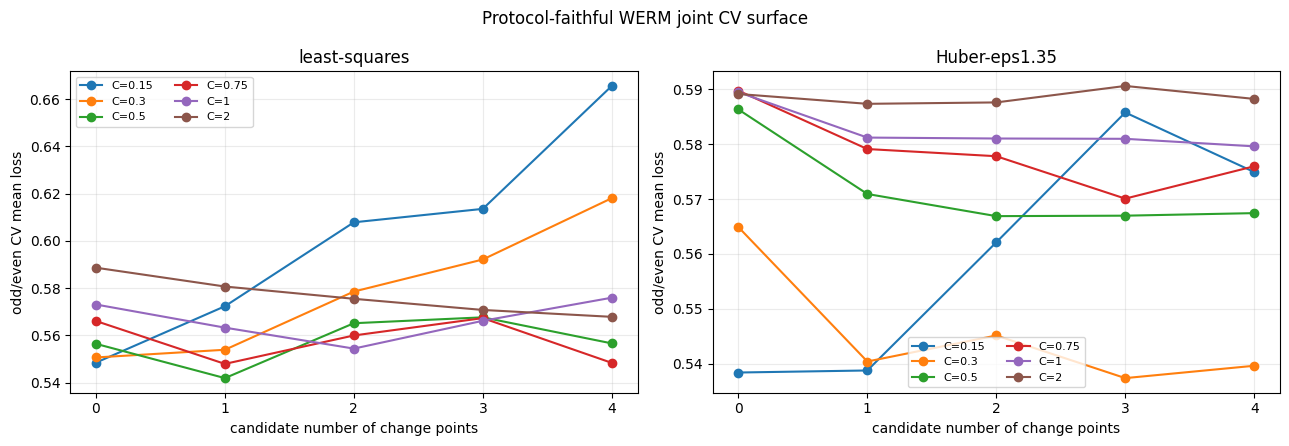

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
for axis, result in zip(axes, primary_results):
    curve = pd.DataFrame(result["score_curve"])
    for constant, group in curve.groupby("constant"):
        axis.plot(group["change_points"], group["cv_mean"], marker="o", label=f"C={constant:g}")
    axis.set_title(result["loss"])
    axis.set_xlabel("candidate number of change points")
    axis.set_ylabel("odd/even CV mean loss")
    axis.set_xticks(range(5))
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8, ncol=2)
fig.suptitle("Protocol-faithful WERM joint CV surface")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "primary_cv_surfaces.png", dpi=180, bbox_inches="tight")
plt.show()

## No-coefficient-penalty control

This control removes both L1 and L2 coefficient penalties while preserving
the corrected loss contract. WERM segmentation and hard segment refits use
the base loss M; absolute loss is used only for held-out CV scoring. Because
p=114, an odd/even training segment can be underdetermined, so these results
are reported as a direct control rather than discarded when they select zero.

In [7]:
unpenalized_results = []
for specification in primary_specs:
    for folds, delta_fraction in [
        (2, 1/40),
        (5, 1/40),
        (2, 1/30),
        (2, 1/20),
    ]:
        print(
            "Running unpenalized",
            specification["loss_name"],
            f"folds={folds}",
            f"delta={delta_fraction:g}",
            flush=True,
        )
        result = werm_cv_surface(
            X, y, **specification,
            segment_counts=(1, 2, 3, 4, 5),
            constants=(0.0,), penalty_norm="none",
            delta_fraction=delta_fraction, num_folds=folds,
            design_mode="reference", standardize_y=False,
        )
        unpenalized_results.append(result)
        print({key: result[key] for key in (
            "loss", "num_folds", "delta_fraction",
            "selected_change_points", "estimated_change_points",
            "estimated_dates", "elapsed_seconds",
        )})

unpenalized_table = pd.DataFrame([{
    "loss": result["loss"], "folds": result["num_folds"],
    "delta": result["delta_fraction"],
    "selected CP count": result["selected_change_points"],
    "indices": result["estimated_change_points"],
    "dates": result["estimated_dates"],
} for result in unpenalized_results])
unpenalized_table

Running unpenalized least-squares folds=2 delta=0.025


\Delta: 1, n: 50, Lmin: 1, Lmax: 1


100%|██████████| 1/1 [00:00<00:00, 4568.96it/s]


\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 4, Lmax: 4
\Delta: 1, n: 50, Lmin: 5, Lmax: 5


100%|██████████| 1/1 [00:00<00:00, 84.41it/s]

100%|██████████| 1/1 [00:00<00:00,  7.21it/s]

  6%|▌         | 11404/194580 [00:00<00:01, 114033.31it/s]


 24%|██▍       | 46886/194580 [00:00<00:01, 117951.87it/s]

... (308 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

{'loss': 'Huber-eps1.35', 'num_folds': 2, 'delta_fraction': 0.05, 'selected_change_points': 0, 'estimated_change_points': [], 'estimated_dates': [], 'elapsed_seconds': 28.51169312465936}


,loss,folds,delta,selected CP count,indices,dates
0,least-squares,2,0.025000,0,[],[]
1,least-squares,5,0.025000,0,[],[]
2,least-squares,2,0.033333,0,[],[]
3,least-squares,2,0.050000,0,[],[]
4,Huber-eps1.35,2,0.025000,0,[],[]
5,Huber-eps1.35,5,0.025000,0,[],[]
6,Huber-eps1.35,2,0.033333,0,[],[]
7,Huber-eps1.35,2,0.050000,0,[],[]


## Stage 2: robustness checks around the winning specifications

A result is stronger if it is not an isolated point on the tuning grid. For
each primary loss, the selected C is checked with five interlaced folds and
with nearby minimum-spacing fractions. Absolute loss remains the CV scoring loss
throughout, while every segment hard fit remains faithful to the base loss M.
Extra fold-local feature z-scoring is tested
only as a method-specific sensitivity, not presented as McScan's protocol.

In [8]:
robustness_results = []
for primary, specification in zip(primary_results, primary_specs):
    selected_C = primary["selected_constant"]
    local_grid = tuple(sorted(set([
        max(0.05, selected_C / 2), selected_C, selected_C * 1.5, selected_C * 2
    ])))
    for folds, delta_fraction, score_name, design_mode in [
        (5, 1/40, "absolute", "reference"),
        (2, 1/30, "absolute", "reference"),
        (2, 1/20, "absolute", "reference"),
        (2, 1/40, "absolute", "fold-zscore"),
    ]:
        score_loss = absolute_loss
        label = (
            f'{specification["loss_name"]}; folds={folds}; delta={delta_fraction:g}; '
            f'score={score_name}; design={design_mode}'
        )
        print("Running", label, flush=True)
        result = werm_cv_surface(
            X, y,
            fit_loss=specification["fit_loss"],
            refit_loss=specification["refit_loss"],
            score_loss=score_loss, loss_name=specification["loss_name"],
            segment_counts=(1, 2, 3, 4, 5), constants=local_grid,
            penalty_norm="l1", delta_fraction=delta_fraction,
            num_folds=folds, design_mode=design_mode, standardize_y=False,
        )
        result["sensitivity_label"] = label
        robustness_results.append(result)
        print(result["selected_change_points"], result["selected_constant"], result["estimated_dates"], flush=True)

robustness_table = pd.DataFrame([{
    "loss": result["loss"], "folds": result["num_folds"],
    "delta": result["delta_fraction"], "score": result["score_loss"],
    "design": result["design_mode"], "selected CP count": result["selected_change_points"],
    "C": result["selected_constant"], "indices": result["estimated_change_points"],
    "dates": result["estimated_dates"],
} for result in robustness_results])
robustness_table

Running least-squares; folds=5; delta=0.025; score=absolute; design=reference


\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 4, Lmax: 4
\Delta: 1, n: 50, Lmin: 4, Lmax: 4
\Delta: 1, n: 50, Lmin: 4, Lmax: 4
\Delta: 1, n: 50, Lmin: 4, Lmax: 4
\Delta: 1, n: 50, Lmin: 5, Lmax: 5
\Delta: 1, n: 50, Lmin: 5, Lmax: 5
\Delta: 1, n: 50, Lmin: 5, Lmax: 5
\Delta: 1, n: 50, Lmin: 5, Lmax: 5


100%|██████████| 1/1 [00:00<00:00, 122.45it/s]

 45%|████▌     | 7813/17296 [00:00<00:00, 78121.88it/s]

100%|██████████| 1/1 [00:00<00:00,  5.69it/s]

100%|██████████| 1/1 [00:00<00:00,  4.95it/s]

100%|██████████| 1/1 [00:00<00:00,  3.87it/s]

 10%|▉         | 19016/194580 [00:00<00:02, 78485.03it/s]


 28%|██▊       | 54130/194580 [00:00<00:01, 111141.75it/s]


 31%|███       | 59518/194580 [00:00<00:01, 86233.76it/s]

... (917 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/48 [00:00<?, ?it/s]

1 0.44999999999999996 ['1991-03']


,loss,folds,delta,score,design,selected CP count,C,indices,dates
0,least-squares,5,0.025000,absolute_loss,reference,0,0.25,[],[]
1,least-squares,2,0.033333,absolute_loss,reference,1,0.50,[528],[2004-01]
2,least-squares,2,0.050000,absolute_loss,reference,1,0.50,[528],[2004-01]
3,least-squares,2,0.025000,absolute_loss,fold-zscore,1,1.00,[525],[2003-10]
4,Huber-eps1.35,5,0.025000,absolute_loss,reference,0,0.15,[],[]
5,Huber-eps1.35,2,0.033333,absolute_loss,reference,3,0.30,"[154, 593, 618]","[1972-11, 2009-06, 2011-07]"
6,Huber-eps1.35,2,0.050000,absolute_loss,reference,3,0.30,"[157, 593, 647]","[1973-02, 2009-06, 2013-12]"
7,Huber-eps1.35,2,0.025000,absolute_loss,fold-zscore,1,0.45,[374],[1991-03]


In [9]:
all_results = primary_results + unpenalized_results + robustness_results
nonzero = [result for result in all_results if result["selected_change_points"] >= 1]

def nearest_reference_months(result):
    if not result["estimated_change_points"]:
        return float("inf")
    targets = np.asarray(reference_indices["McScan"] + reference_indices["DPDU_different_window"])
    return int(min(
        abs(int(change) - int(target))
        for change in result["estimated_change_points"] for target in targets
    ))

ranked_nonzero = sorted(nonzero, key=lambda result: (
    result["design_mode"] != "reference",
    0,
    nearest_reference_months(result),
    result["num_folds"] != 2,
))
recommended = ranked_nonzero[0] if ranked_nonzero else None

summary = {
    "created_by": "FRED-MD Real Data Exploration.ipynb",
    "data_audit": data_audit,
    "reference_protocol": {
        "McScan_dates": reference_dates["McScan"],
        "DPDU_dates_different_window": reference_dates["DPDU_different_window"],
        "primary_fold_scheme": "odd/even interlaced",
        "primary_refit_rule": "same loss as WERM fitting loss",
        "primary_score_rule": "absolute loss only on held-out predictions",
    },
    "primary_results": primary_results,
    "unpenalized_results": unpenalized_results,
    "robustness_results": robustness_results,
    "recommended": recommended,
    "diagnosis": [
        "Unpenalized segment refits are high variance when p=114 and fold/segment sample sizes are small.",
        "The previous helper used M_scorer for coefficient refits, so MAE scoring silently changed LS/Huber validation estimation to absolute-loss regression.",
        "Changing num_folds alone cannot repair the missing coefficient regularization or loss mismatch.",
        "McScan and DPDU published dates come from materially different selection rules; agreement should be approximate, not forced.",
    ],
}

summary_path = RESULT_DIR / "summary.json"
with summary_path.open("w") as handle:
    json.dump(summary, handle, indent=2)

flat_rows = []
for phase, results in (
    ("primary", primary_results),
    ("unpenalized", unpenalized_results),
    ("robustness", robustness_results),
):
    for result in results:
        flat_rows.append({
            "phase": phase, "loss": result["loss"],
            "refit_loss": result["refit_loss"], "score_loss": result["score_loss"],
            "penalty_norm": result["penalty_norm"], "delta_fraction": result["delta_fraction"],
            "num_folds": result["num_folds"], "design_mode": result["design_mode"],
            "selected_change_points": result["selected_change_points"],
            "selected_constant": result["selected_constant"],
            "estimated_change_points": ";".join(map(str, result["estimated_change_points"])),
            "estimated_dates": ";".join(result["estimated_dates"]),
            "nearest_reference_months": nearest_reference_months(result),
        })
pd.DataFrame(flat_rows).to_csv(RESULT_DIR / "selections.csv", index=False)

print("Saved", summary_path)
if recommended is None:
    print("No nonzero CV selection found in the audited grid.")
else:
    print("RECOMMENDED REPRODUCIBLE NONZERO SETTING")
    print(json.dumps({key: recommended[key] for key in (
        "loss", "refit_loss", "score_loss", "penalty_norm", "selected_constant",
        "delta_fraction", "num_folds", "design_mode", "selected_change_points",
        "estimated_change_points", "estimated_dates"
    )}, indent=2))
    print("Nearest bundled reference date distance (months):", nearest_reference_months(recommended))

Saved /scratch/ga442/gab-code-env/papers/WeightedERM-reference/results/FRED-MD_real-data-exploration/summary.json
RECOMMENDED REPRODUCIBLE NONZERO SETTING
{
  "loss": "Huber-eps1.35",
  "refit_loss": "huber",
  "score_loss": "absolute_loss",
  "penalty_norm": "l1",
  "selected_constant": 0.3,
  "delta_fraction": 0.025,
  "num_folds": 2,
  "design_mode": "reference",
  "selected_change_points": 3,
  "estimated_change_points": [
    154,
    593,
    613
  ],
  "estimated_dates": [
    "1972-11",
    "2009-06",
    "2011-02"
  ]
}
Nearest bundled reference date distance (months): 9


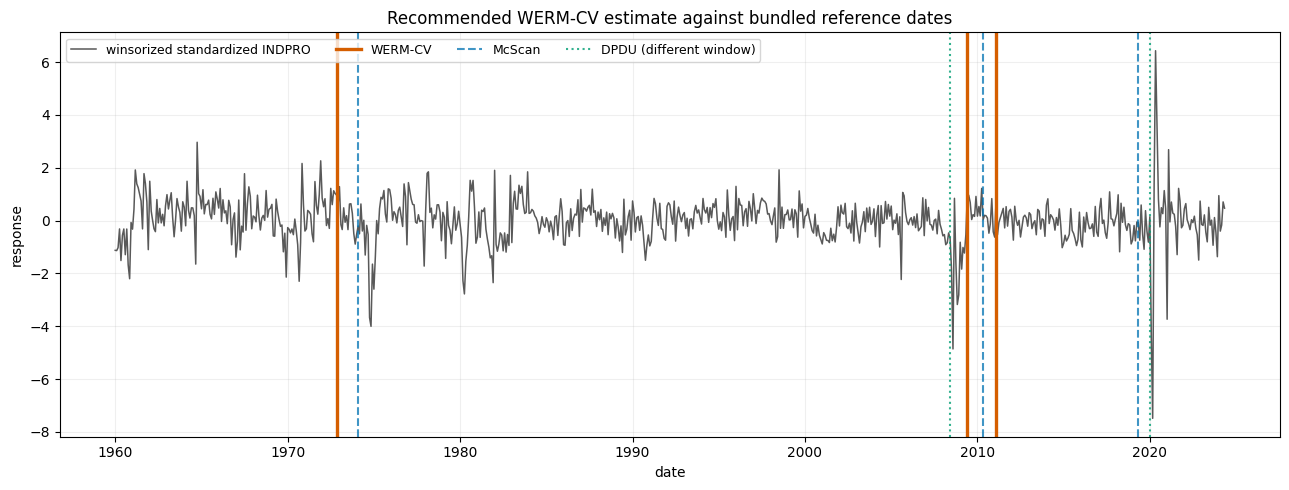

In [10]:
if recommended is not None:
    figure, axis = plt.subplots(figsize=(13, 5))
    axis.plot(pd.to_datetime(dates), y, color="0.35", linewidth=1.1, label="winsorized standardized INDPRO")
    for index, value in enumerate(recommended["estimated_change_points"]):
        axis.axvline(pd.Timestamp(str(dates[value])), color="#D55E00", linewidth=2.4,
                     label="WERM-CV" if index == 0 else None)
    for index, value in enumerate(reference_indices["McScan"]):
        axis.axvline(pd.Timestamp(str(dates[value])), color="#0072B2", linestyle="--", alpha=0.75,
                     label="McScan" if index == 0 else None)
    for index, value in enumerate(reference_indices["DPDU_different_window"]):
        axis.axvline(pd.Timestamp(str(dates[value])), color="#009E73", linestyle=":", alpha=0.8,
                     label="DPDU (different window)" if index == 0 else None)
    axis.set_title("Recommended WERM-CV estimate against bundled reference dates")
    axis.set_xlabel("date")
    axis.set_ylabel("response")
    axis.grid(alpha=0.2)
    axis.legend(ncol=4, fontsize=9)
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / "recommended_change_points.png", dpi=200, bbox_inches="tight")
    plt.show()

## Interpreting the knobs

1. **Coefficient penalty is the first knob to tune.** With 114 predictors,
   zero or weak regularization makes validation segment fits unstable,
   especially under two-fold CV and multi-segment candidates. Jointly tune C
   with segment count; do not tune count while leaving segment regressions
   effectively unregularized.
2. **Keep segmentation and hard-refit losses aligned with the base loss M.**
   Least squares uses squared loss for both fits; Huber uses the same epsilon for
   both fits. Absolute loss is used only on held-out predictions for CV scoring
   and must never silently become the coefficient-fitting loss.
3. **Use two interlaced folds as the closest DPDU comparison.** Five folds are a
   stability check. More folds increase training size but do not solve the
   p-versus-segment-size problem and are not more time-respecting.
4. **Huber epsilon is meaningful only relative to response scale.** Here y has
   standard deviation about 0.88 after the reference preprocessing, so 1.35 is
   a moderate robust threshold. If `standardize_y=True`, scale both training
   and validation y by the training-fold standard deviation and interpret
   epsilon on that standardized scale.
5. **Retain the 99.9% truncation for the main comparison.** It is explicitly in
   McScan's pipeline and removes only the most extreme transformed values.
   Removing it is a sensitivity analysis, not a closer replication.
6. **Do not add an intercept by default.** The source series are centered before
   PCA/idiosyncratic construction and y is nearly centered. If an intercept is
   added, it should not be penalized; the old exploratory code penalized it.
7. **Minimum spacing (`delta_fraction`) is a structural assumption, not a free
   reward for finding more points.** Values around 1/40--1/20 allow 19--39
   months at full n and remain close to the existing WERM experiments. Large
   values can suppress nearby events; tiny values invite unstable short
   segments.
8. **Extra feature z-scoring is WERM-specific.** It can be defensible because
   L1 penalties depend on feature scale, but it is not literally the bundled
   McScan design. Report it separately unless the reference-design result is
   inadequate.